# 04. Final Validation & Stratified Train/Test Partitioning
## Rheumatoid Arthritis Classification System

### Executive Purpose
This notebook establishes the single, standardized, reproducible train/test partition for the entire team:
1. **Stratified 80:20 Partitioning**: Generates a stratified train (80%, 9,668 records) and test (20%, 2,417 records) split using a fixed random seed (`SEED = 42`).
2. **Traceability Preservation**: Preserves the original `patient_row_id` and clinical `Disease` label in the split files for auditability.
3. **Strict Zero-Leakage Guarantee**: Verifies absolute mathematical non-overlap ($Train \cap Test = \emptyset$).
4. **Target Balance Verification**: Confirms that the target ratio (~23.57% RA) is precisely maintained in both partitions.
5. **No Global Transformations**: Verifies that no scalers, encoders, or imputers are fit across the dataset; model owners will fit preprocessing strictly on `X_train`.
6. **Artifact Export**: Saves `data/splits/train.csv`, `data/splits/test.csv`, and `data/splits/split_metadata.json`.
7. **End-to-End Loader Verification**: Tests `src/data_loader.py` functions to verify the contract for all downstream model notebooks.


In [1]:
import sys
import os
from pathlib import Path
import json
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)

root = Path("..").resolve() if Path("..").resolve().name == "RA_Project" else Path(".").resolve()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.data_loader import (
    load_engineered_data,
    load_train_data,
    load_test_data,
    load_split_metadata,
    get_feature_names,
    FEATURE_COLUMNS,
    TARGET_COLUMN,
    ID_COLUMN,
    TRACE_COLUMN
)

print(f"Project root resolved to: {root}")


Project root resolved to: D:\PRJ 1 Sem 5\RA_Project


## 1. Load Processed Cohort
We load the engineered dataset produced in Notebook 03 (`data/processed/ra_engineered_dataset.csv`).


In [2]:
df_engineered = load_engineered_data(return_X_y=False)
print(f"Loaded engineered cohort: {df_engineered.shape[0]:,} records across {df_engineered.shape[1]} columns")

assert df_engineered.shape == (12085, 17), f"Expected (12085, 17), found {df_engineered.shape}"
assert set(df_engineered[TARGET_COLUMN].unique()) == {0, 1}, "Invalid target labels found!"
print("Engineered dataset integrity verified.")


Loaded engineered cohort: 12,085 records across 17 columns
Engineered dataset integrity verified.


## 2. Reproducible Stratified 80:20 Partitioning
We partition the dataset into 80% training and 20% testing sets using `random_state=42` and `stratify=Target_RA`.


In [3]:
RANDOM_SEED = 42
TEST_SIZE = 0.20

train_df, test_df = train_test_split(
    df_engineered,
    test_size=TEST_SIZE,
    random_state=RANDOM_SEED,
    stratify=df_engineered[TARGET_COLUMN],
    shuffle=True
)

print(f"Total Cohort: {len(df_engineered):,} records (100.0%)")
print(f"Training Set: {len(train_df):,} records ({len(train_df)/len(df_engineered)*100:.1f}%)")
print(f"Testing Set:  {len(test_df):,} records ({len(test_df)/len(df_engineered)*100:.1f}%)")

assert len(train_df) == 9668, f"Expected 9,668 train records, got {len(train_df)}"
assert len(test_df) == 2417, f"Expected 2,417 test records, got {len(test_df)}"


Total Cohort: 12,085 records (100.0%)
Training Set: 9,668 records (80.0%)
Testing Set:  2,417 records (20.0%)


## 3. Strict Non-Overlap & Stratification Verification
We assert zero leakage and verify exact proportional class preservation between splits.


In [4]:
# 1. Non-Overlap Verification
train_ids = set(train_df[ID_COLUMN])
test_ids = set(test_df[ID_COLUMN])
overlap = train_ids.intersection(test_ids)

print(f"Unique Train IDs: {len(train_ids):,}")
print(f"Unique Test IDs:  {len(test_ids):,}")
print(f"ID Overlap Count: {len(overlap)}")
assert len(overlap) == 0, f"FATAL ERROR: Train and Test partitions share {len(overlap)} records!"

# 2. Target Proportion Stratification Verification
train_target_counts = train_df[TARGET_COLUMN].value_counts()
test_target_counts = test_df[TARGET_COLUMN].value_counts()

split_comparison = pd.DataFrame({
    'Train Count': train_target_counts,
    'Train Ratio (%)': (train_df[TARGET_COLUMN].value_counts(normalize=True) * 100).round(2),
    'Test Count': test_target_counts,
    'Test Ratio (%)': (test_df[TARGET_COLUMN].value_counts(normalize=True) * 100).round(2),
    'Full Cohort Ratio (%)': (df_engineered[TARGET_COLUMN].value_counts(normalize=True) * 100).round(2),
}, index=[1, 0])
split_comparison.index = ['Rheumatoid Arthritis (1)', 'Non-RA (0)']

print("\nClass Distribution Stratification Across Splits:")
display(split_comparison)

# Verify ratio difference is negligible (< 0.05%)
diff = abs(split_comparison.loc['Rheumatoid Arthritis (1)', 'Train Ratio (%)'] - 
           split_comparison.loc['Rheumatoid Arthritis (1)', 'Test Ratio (%)'])
print(f"\nStratification disparity: {diff:.4f}%")
assert diff < 0.1, f"Excessive stratification imbalance: {diff}%"


Unique Train IDs: 9,668
Unique Test IDs:  2,417
ID Overlap Count: 0

Class Distribution Stratification Across Splits:


,Train Count,Train Ratio (%),Test Count,Test Ratio (%),Full Cohort Ratio (%)
Rheumatoid Arthritis (1),2278,23.56,570,23.58,23.57
Non-RA (0),7390,76.44,1847,76.42,76.43



Stratification disparity: 0.0200%


## 4. Distributional Fidelity Between Splits
We visualize key feature distributions (Age, RF, ESR, Anti-CCP) across Train and Test splits to confirm absence of distributional drift.


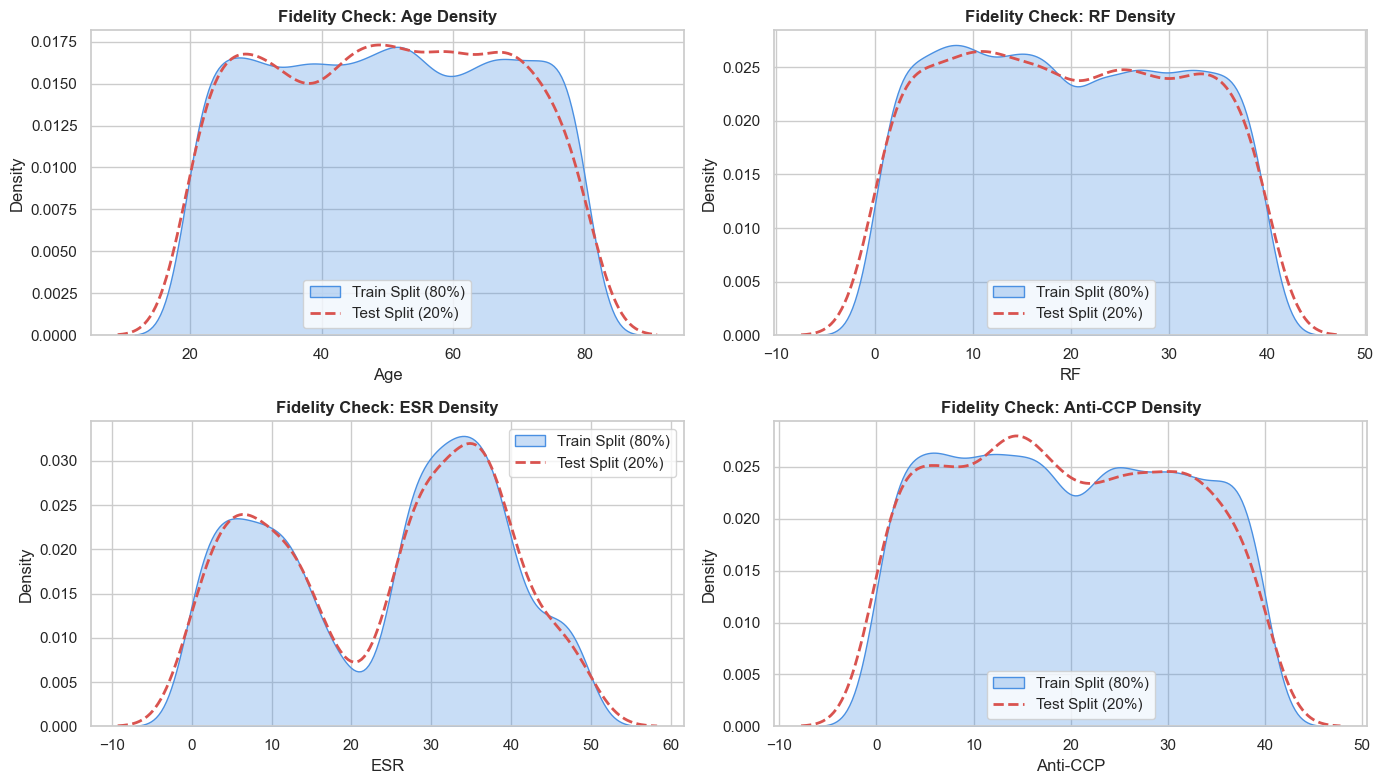

Density overlay confirms identical feature distributions between train and test partitions.


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

sample_features = ['Age', 'RF', 'ESR', 'Anti-CCP']
for idx, col in enumerate(sample_features):
    ax = axes[idx // 2, idx % 2]
    sns.kdeplot(train_df[col].dropna(), ax=ax, label='Train Split (80%)', color='#4a90e2', fill=True, alpha=0.3)
    sns.kdeplot(test_df[col].dropna(), ax=ax, label='Test Split (20%)', color='#d9534f', linestyle='--', linewidth=2)
    ax.set_title(f"Fidelity Check: {col} Density", fontweight='bold')
    ax.legend()

plt.tight_layout()
plt.show()
print("Density overlay confirms identical feature distributions between train and test partitions.")


## 5. Partition Persistence & Metadata Export
We write the finalized partitions and metadata to `data/splits/`.


In [6]:
splits_dir = root / "data" / "splits"
splits_dir.mkdir(parents=True, exist_ok=True)

train_path = splits_dir / "train.csv"
test_path = splits_dir / "test.csv"
meta_path = splits_dir / "split_metadata.json"

train_df.to_csv(train_path, index=False)
test_df.to_csv(test_path, index=False)

split_meta = {
    "creation_timestamp": datetime.datetime.now(datetime.timezone.utc).isoformat(),
    "random_state": RANDOM_SEED,
    "test_size_fraction": TEST_SIZE,
    "stratify_column": TARGET_COLUMN,
    "shuffle": True,
    "total_cohort_records": len(df_engineered),
    "train_split": {
        "record_count": len(train_df),
        "fraction": len(train_df) / len(df_engineered),
        "target_distribution": {
            "positive_RA_count": int(train_target_counts[1]),
            "positive_RA_ratio": float(train_target_counts[1] / len(train_df)),
            "negative_non_RA_count": int(train_target_counts[0]),
            "negative_non_RA_ratio": float(train_target_counts[0] / len(train_df))
        }
    },
    "test_split": {
        "record_count": len(test_df),
        "fraction": len(test_df) / len(df_engineered),
        "target_distribution": {
            "positive_RA_count": int(test_target_counts[1]),
            "positive_RA_ratio": float(test_target_counts[1] / len(test_df)),
            "negative_non_RA_count": int(test_target_counts[0]),
            "negative_non_RA_ratio": float(test_target_counts[0] / len(test_df))
        }
    },
    "zero_overlap_confirmed": len(overlap) == 0,
    "feature_columns_count": len(FEATURE_COLUMNS),
    "feature_columns": FEATURE_COLUMNS,
    "traceability_columns": [ID_COLUMN, TRACE_COLUMN]
}

with open(meta_path, "w", encoding="utf-8") as f:
    json.dump(split_meta, f, indent=2)

print(f"Saved train split: {train_path} ({train_path.stat().st_size / 1024:.1f} KB)")
print(f"Saved test split:  {test_path} ({test_path.stat().st_size / 1024:.1f} KB)")
print(f"Saved split metadata: {meta_path}")


Saved train split: D:\PRJ 1 Sem 5\RA_Project\data\splits\train.csv (968.1 KB)
Saved test split:  D:\PRJ 1 Sem 5\RA_Project\data\splits\test.csv (242.4 KB)
Saved split metadata: D:\PRJ 1 Sem 5\RA_Project\data\splits\split_metadata.json


## 6. End-to-End Interface Validation via `src.data_loader`
We simulate how teammates will load data in their respective model notebooks.


In [7]:
# Test load_train_data
X_tr, y_tr = load_train_data(return_X_y=True)
X_te, y_te = load_test_data(return_X_y=True)

# Contract validations
assert X_tr.shape == (9668, 14), f"X_train shape error: {X_tr.shape}"
assert y_tr.shape == (9668,), f"y_train shape error: {y_tr.shape}"
assert X_te.shape == (2417, 14), f"X_test shape error: {X_te.shape}"
assert y_te.shape == (2417,), f"y_test shape error: {y_te.shape}"

# Leakage checks
assert "Disease" not in X_tr.columns, "Target leakage: Disease in X_train!"
assert "Target_RA" not in X_tr.columns, "Target leakage: Target_RA in X_train!"
assert "patient_row_id" not in X_tr.columns, "Leakage: patient_row_id in X_train!"
assert list(X_tr.columns) == list(X_te.columns), "Feature order mismatch between train and test!"

# Metadata check
meta_loaded = load_split_metadata()
assert meta_loaded["zero_overlap_confirmed"] is True

print("=" * 65)
print("FINAL ACCEPTANCE VALIDATION PASSED!")
print(f"X_train: {X_tr.shape} | y_train: {y_tr.shape} ({y_tr.mean():.2%} RA)")
print(f"X_test:  {X_te.shape} | y_test:  {y_te.shape} ({y_te.mean():.2%} RA)")
print("No leakage, standardized feature ordering, zero overlap.")
print("=" * 65)


FINAL ACCEPTANCE VALIDATION PASSED!
X_train: (9668, 14) | y_train: (9668,) (23.56% RA)
X_test:  (2417, 14) | y_test:  (2417,) (23.58% RA)
No leakage, standardized feature ordering, zero overlap.
